In [1]:
# Cell 1 — setup: load every table we'll use, parse dates into NEW columns
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = PROJECT / "data" / "raw"
FIGS = PROJECT / "reports" / "figures"
csv_files = sorted(RAW.rglob("*.csv"))

def load(name):
    matches = [f for f in csv_files if f.name == name]
    assert len(matches) == 1, f"Expected 1 file called {name}, found {len(matches)}"
    return pd.read_csv(matches[0])

FMT = "%m/%d/%Y %I:%M:%S %p"
daily  = load("dailyActivity_merged.csv")
sleep  = load("sleepDay_merged.csv")
weight = load("weightLogInfo_merged.csv")
heart  = load("heartrate_seconds_merged.csv")      # the slow one: 5–15 seconds
hourly = load("hourlySteps_merged.csv")
minute_sleep = load("minuteSleep_merged.csv")

daily["activity_date"]      = pd.to_datetime(daily["ActivityDate"], format="%m/%d/%Y")
sleep["sleep_date"]         = pd.to_datetime(sleep["SleepDay"], format=FMT)
weight["log_time"]          = pd.to_datetime(weight["Date"], format=FMT)
heart["reading_time"]       = pd.to_datetime(heart["Time"], format=FMT)
hourly["activity_hour"]     = pd.to_datetime(hourly["ActivityHour"], format=FMT)
minute_sleep["minute_time"] = pd.to_datetime(minute_sleep["date"], format=FMT)

# Stage 1 decision: remove the 3 exact duplicate sleep rows (the raw table stays untouched)
sleep_clean = sleep.drop_duplicates().copy()

print("Running from .venv?", ".venv" in sys.executable)
for name, df in [("daily", daily), ("sleep_clean", sleep_clean), ("weight", weight), ("heart", heart),
                 ("hourly", hourly), ("minute_sleep", minute_sleep)]:
    print(f"{name:13s} rows={len(df):>10,}  users={df['Id'].nunique():>3}")

Running from .venv? True
daily         rows=       940  users= 33
sleep_clean   rows=       410  users= 24
weight        rows=        67  users=  8
heart         rows= 2,483,658  users= 14
hourly        rows=    22,099  users= 33
minute_sleep  rows=   188,521  users= 24


In [2]:
# Cell 2 — non-wear days: how many days look like the tracker wasn't worn?
minute_cols = ["VeryActiveMinutes", "FairlyActiveMinutes", "LightlyActiveMinutes", "SedentaryMinutes"]
daily["minutes_recorded"] = daily[minute_cols].sum(axis=1)
daily["non_wear"] = (daily["TotalSteps"] == 0) & (daily["SedentaryMinutes"] == 1440)   # definition from Stage 1

print("Total days:", len(daily))
print("Non-wear days (0 steps AND 1,440 sedentary minutes):", daily["non_wear"].sum(),
      f"({daily['non_wear'].mean():.1%}), users affected: {daily.loc[daily['non_wear'], 'Id'].nunique()}")
print("Days with 0 steps but NOT 1,440 sedentary minutes:",
      ((daily["TotalSteps"] == 0) & ~daily["non_wear"]).sum())
print("Days with exactly 1,440 minutes recorded:", (daily["minutes_recorded"] == 1440).sum())
print("Days with fewer than 1,440 minutes recorded:", (daily["minutes_recorded"] < 1440).sum())
print("\nDays of data per user (worn days only):")
print(daily.loc[~daily["non_wear"]].groupby("Id").size().describe().round(1))

Total days: 940
Non-wear days (0 steps AND 1,440 sedentary minutes): 72 (7.7%), users affected: 15
Days with 0 steps but NOT 1,440 sedentary minutes: 5
Days with exactly 1,440 minutes recorded: 478
Days with fewer than 1,440 minutes recorded: 462

Days of data per user (worn days only):
count    33.0
mean     26.3
std       6.7
min       3.0
25%      22.0
50%      30.0
75%      31.0
max      31.0
dtype: float64


In [3]:
# Cell 3 — workout days, using the Stage 1 definition (very + fairly active minutes >= 30)
daily["mvpa_minutes"] = daily["VeryActiveMinutes"] + daily["FairlyActiveMinutes"]
daily["workout_day"] = daily["mvpa_minutes"] >= 30
worn = daily.loc[~daily["non_wear"]]

print(f"Workout days: {worn['workout_day'].sum()} of {len(worn)} worn days ({worn['workout_day'].mean():.1%})")
per_user = worn.groupby("Id")["workout_day"].mean()
print("Users with NO workout days:", (per_user == 0).sum(), "| users with workouts on over half their days:",
      (per_user > 0.5).sum())
print("\nAverage steps — workout days vs other worn days:")
print(worn.groupby("workout_day")["TotalSteps"].agg(["count", "mean", "median"]).round(0))

Workout days: 398 of 868 worn days (45.9%)
Users with NO workout days: 4 | users with workouts on over half their days: 14

Average steps — workout days vs other worn days:
             count     mean   median
workout_day                         
False          470   5418.0   5274.0
True           398  11641.0  11196.0


In [4]:
# Cell 4 — check the Stage 1 assumption: is SleepDay the day the person WOKE UP?
ms = minute_sleep.drop_duplicates().copy()
ms["is_asleep"] = ms["value"].eq(1)                        # 1 = asleep, 2 = restless, 3 = awake
sessions = (ms.groupby(["Id", "logId"])
              .agg(start=("minute_time", "min"), end=("minute_time", "max"), asleep=("is_asleep", "sum"))
              .reset_index())
sessions["start_date"] = sessions["start"].dt.normalize()
sessions["end_date"]   = sessions["end"].dt.normalize()
print("Sleep sessions:", len(sessions), "| crossing midnight:",
      f"{(sessions['start_date'] != sessions['end_date']).mean():.1%}")

for rule in ["start_date", "end_date"]:
    per_day = (sessions.groupby(["Id", rule])
                       .agg(asleep=("asleep", "sum"), records=("logId", "count"))
                       .reset_index().rename(columns={rule: "sleep_date"}))
    m = sleep_clean.merge(per_day, on=["Id", "sleep_date"], how="left")
    diff = (m["asleep"] - m["TotalMinutesAsleep"]).abs()
    print(f"\nIf SleepDay = {rule:10s}: no matching session {m['asleep'].isna().mean():6.1%} | "
          f"asleep minutes exactly equal {(diff == 0).mean():6.1%} | within 5 min {(diff <= 5).mean():6.1%} | "
          f"same number of sleeps {(m['records'] == m['TotalSleepRecords']).mean():6.1%}")

Sleep sessions: 459 | crossing midnight: 55.3%

If SleepDay = start_date: no matching session  14.9% | asleep minutes exactly equal  30.0% | within 5 min  33.4% | same number of sleeps  75.9%

If SleepDay = end_date  : no matching session   0.0% | asleep minutes exactly equal  96.6% | within 5 min  98.5% | same number of sleeps 100.0%


In [5]:
# Cell 5 — size check for the database: how much should heart rate be summarised? Plus a hourly-steps check
heart["minute"] = heart["reading_time"].dt.floor("min")
heart["hour"]   = heart["reading_time"].dt.floor("h")
per_minute = heart.groupby(["Id", "minute"]).size()
per_hour   = heart.groupby(["Id", "hour"]).size()
print(f"Heart rate raw readings: {len(heart):,}")
print(f"  ...one row per user per minute: {len(per_minute):,}")
print(f"  ...one row per user per hour:   {len(per_hour):,} (median {per_hour.median():.0f} readings per hour)")

# Known fact to check: a day's hourly steps should add up to that day's TotalSteps
hourly["activity_date"] = hourly["activity_hour"].dt.normalize()
hourly_sum = hourly.groupby(["Id", "activity_date"])["StepTotal"].sum().rename("hourly_total").reset_index()
check = daily.merge(hourly_sum, on=["Id", "activity_date"], how="inner")
gap = (check["hourly_total"] - check["TotalSteps"]).abs()
print(f"\nDays in both tables: {len(check)} | hourly steps exactly equal daily total: {(gap == 0).mean():.1%} | "
      f"within 1%: {(gap <= 0.01 * check['TotalSteps'].clip(lower=1)).mean():.1%}")

Heart rate raw readings: 2,483,658
  ...one row per user per minute: 333,420
  ...one row per user per hour:   6,013 (median 379 readings per hour)

Days in both tables: 934 | hourly steps exactly equal daily total: 83.0% | within 1%: 94.0%


In [6]:
# Cell 6 — weight: how reliable is it?
print("Weight entries per user:")
print(weight.groupby("Id").size().sort_values(ascending=False).to_string())
print(f"\nManual entries: {weight['IsManualReport'].mean():.0%} | entries with a Fat value: {weight['Fat'].notna().sum()} of {len(weight)}")
print("Logged at exactly 23:59:59:", (weight["log_time"].dt.strftime("%H:%M:%S") == "23:59:59").sum())

Weight entries per user:
Id
6962181067    30
8877689391    24
4558609924     5
1503960366     2
2873212765     2
4319703577     2
1927972279     1
5577150313     1

Manual entries: 61% | entries with a Fat value: 2 of 67
Logged at exactly 23:59:59: 41


             mean  count
weekday                 
Monday     8488.0    110
Tuesday    8885.0    139
Wednesday  8158.0    139
Thursday   8064.0    135
Friday     7821.0    120
Saturday   8791.0    115
Sunday     7627.0    110


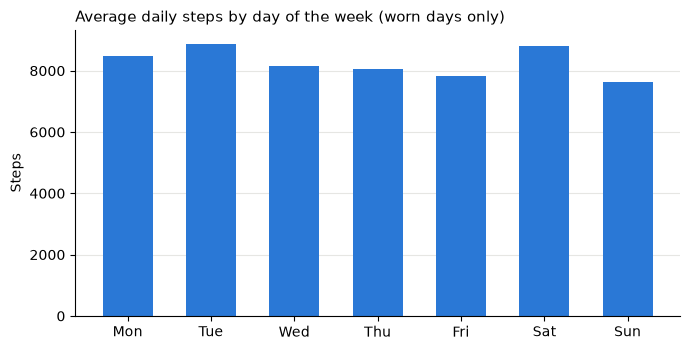

In [7]:
# Cell 7 — chart 1: average steps by day of the week (worn days only), saved for the README
FIGS.mkdir(parents=True, exist_ok=True)
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = (worn.assign(weekday=worn["activity_date"].dt.day_name())
              .groupby("weekday")["TotalSteps"].agg(["mean", "count"]).reindex(order))
print(by_day.round(0))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar([d[:3] for d in order], by_day["mean"], width=0.6, color="#2a78d6")
ax.set_title("Average daily steps by day of the week (worn days only)", loc="left", fontsize=11)
ax.set_ylabel("Steps")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGS / "steps_by_weekday.png", dpi=150)
plt.show()

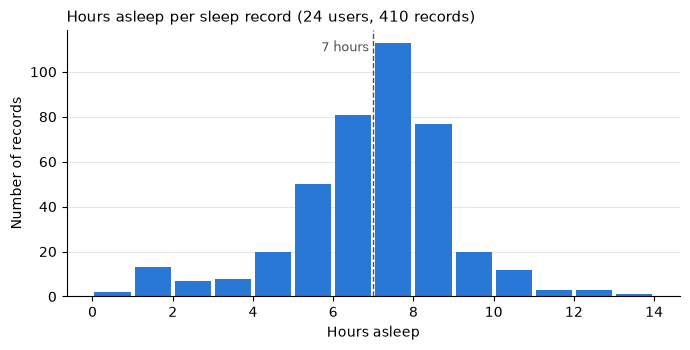

Under 7 hours: 44% of records | median 7.2 hours


In [9]:
# Cell 8 — chart 2: how long do people sleep? (one bar per hour of sleep)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(sleep_clean["TotalMinutesAsleep"] / 60, bins=range(0, 15), color="#2a78d6", rwidth=0.9)
ax.axvline(7, color="#52514e", linestyle="--", linewidth=1)
ax.text(6.9, ax.get_ylim()[1] * 0.92, "7 hours", color="#52514e", fontsize=9, ha="right")
ax.set_title(f"Hours asleep per sleep record ({sleep_clean['Id'].nunique()} users, {len(sleep_clean)} records)",
             loc="left", fontsize=11)
ax.set_xlabel("Hours asleep")
ax.set_ylabel("Number of records")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGS / "sleep_hours.png", dpi=150)
plt.show()
print(f"Under 7 hours: {(sleep_clean['TotalMinutesAsleep'] < 420).mean():.0%} of records | "
      f"median {sleep_clean['TotalMinutesAsleep'].median() / 60:.1f} hours")

## Notes and findings — Notebook 01 (explore)

**Tables:** daily 940 rows / 33 IDs · sleep 410 (after removing 3 duplicates) / 24 · weight 67 / 8 · heart rate 2,483,658 readings / 14 · hourly steps 22,099 / 33 · minute sleep 188,521 / 24.

**Non-wear days:** 72 of 940 (7.7%), across 15 users, are excluded from averages (0 steps and 1,440 sedentary minutes). Worn days per user: median 30, minimum 3. 5 days have 0 steps but some activity minutes; they are kept, because the Stage 1 rule was fixed in advance. 462 days record fewer than 1,440 minutes, most likely because sleep time isn't counted in the activity minutes.

**Workout days** (very + fairly active ≥ 30 min): 398 of 868 worn days (45.9%). 4 users have none, 14 have them on over half their days. They average 11,641 steps vs 5,418, but this is partly circular, because walking creates active minutes.

**Sleep dating confirmed:** dating each sleep by when it *ended* matches `sleepDay` for 96.6% of records exactly (100% for the number of sleeps), vs 30.0% when dating by start. `sleep_date` = the day the person woke up. 55.3% of sleeps cross midnight.

**Heart rate:** stored as one row per user per hour (6,013 rows: average, minimum, maximum, readings), not 333,420 per-minute rows or 2.48M raw readings. Median 379 readings per hour.

**Hourly vs daily steps:** equal on 83.0% of 934 days, within 1% on 94.0%. Daily totals come from `daily_activity`; hourly steps are only for time-of-day questions.

**Weight:** 2 users made 54 of 67 entries; 61% were manual; Fat recorded in 2 of 67. Weight answers need a warning.

**Steps by weekday** (worn days): highest Tuesday 8,885, lowest Sunday 7,627, with 110–139 days per weekday. Too few days to claim a weekly pattern.

**Sleep:** median 7.2 hours; 44% of records under 7 hours.

**Charts saved:** `reports/figures/steps_by_weekday.png`, `reports/figures/sleep_hours.png`.